# 2.3 Gene Expression Analysis & 2.4 Functional Analysis

### Prerequisites & Setup
Ensure you have `fastqc`, `salmon`, `cufflinks` (Tuxedo), R (with DESeq2), and Python libraries installed. 

```python
# Install required Python libraries
!pip install pandas numpy scipy matplotlib seaborn rpy2 requests gseapy
```

In [1]:
import pandas as pd
import numpy as np

# 1. Load the Tuxedo (Cuffdiff) results directly
# Pandas can read .gz files natively if you haven't extracted it
diff_file = "GSE122125_gene_exp.diff.gz" 
df = pd.read_csv(diff_file, sep='\t')

# 2. Keep only successful statistical tests
df = df[df['status'] == 'OK']

# 3. Apply significance thresholds: FDR (q_value in Cuffdiff) < 0.05 and |log2FoldChange| > 2
# Note: Cuffdiff column names are 'q_value' and 'log2(fold_change)'
degs = df[(df['q_value'] < 0.05) & (df['log2(fold_change)'].abs() > 2)]
print(f"Total significant DEGs before biotype filtering: {len(degs)}")

# 4. Filter out unwanted RNA types (rRNA, miRNA, piRNA, etc.)
# If you have a WormBase biotype mapping file, merge it here.
# For demonstration, we assume a 'gene_biotypes.csv' mapping Ensembl IDs to biotypes
try:
    biotypes = pd.read_csv("gene_biotypes.csv") 
    degs_merged = degs.merge(biotypes, left_on='gene_id', right_on='gene_id', how='left')
    unwanted_types = ['miRNA', 'piRNA', 'rRNA', 'ncRNA', 'unconfirmed']
    final_degs = degs_merged[~degs_merged['biotype'].isin(unwanted_types)]
except FileNotFoundError:
    print("Biotype file not found. Proceeding with all DEGs.")
    final_degs = degs

print(f"Final DEGs for functional analysis: {len(final_degs)}")

# 5. Export for Functional Analysis (DAVID, KEGG, Cytoscape)
# Extract just the gene identifiers (usually 'gene' or 'gene_id' column)
gene_list = final_degs['gene_id'].dropna().unique().tolist()

with open('deg_gene_list.txt', 'w') as f:
    for gene in gene_list:
        f.write(f"{gene}\n")
        
print("Gene list exported to 'deg_gene_list.txt' for functional analysis tools.")

Total significant DEGs before biotype filtering: 10796
Biotype file not found. Proceeding with all DEGs.
Final DEGs for functional analysis: 10796
Gene list exported to 'deg_gene_list.txt' for functional analysis tools.


In [2]:
print(degs.columns)

Index(['test_id', 'gene_id', 'gene', 'locus', 'sample_1', 'sample_2', 'status',
       'value_1', 'value_2', 'log2(fold_change)', 'test_stat', 'p_value',
       'q_value', 'significant'],
      dtype='str')


<>:94: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:94: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/900238938.py:94: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/matplotlib/transforms.py:349: RuntimeWarning: invalid value encountered in scalar subtract
  return points[1, 0] - points[0, 0]
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/adjustText/__init__.py:35: RuntimeWarning: invalid value encountered in scalar multiply
  ub = ((x2 - x1) * (y1 - y3) - (y2 - y1)

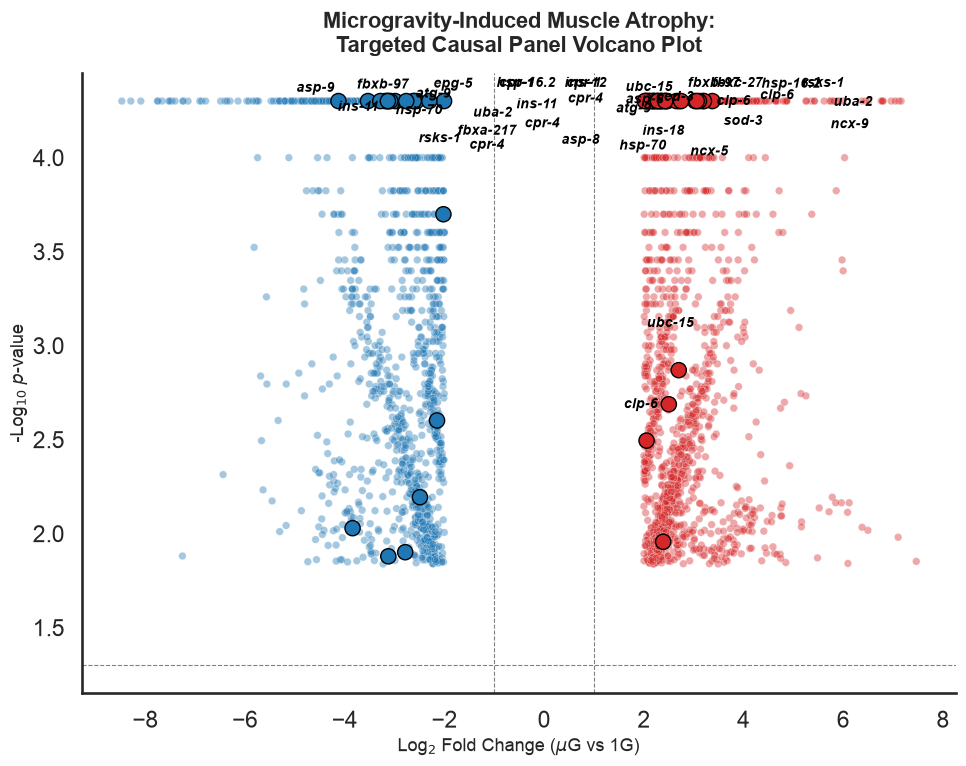

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from adjustText import adjust_text

# 1. Define your Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Prepare Volcano Plot Data
volcano_df = degs.copy()
volcano_df['log2(fold_change)'] = pd.to_numeric(volcano_df['log2(fold_change)'], errors='coerce')
volcano_df['p_value'] = pd.to_numeric(volcano_df['p_value'], errors='coerce')
volcano_df = volcano_df.dropna(subset=['log2(fold_change)', 'p_value'])

# Calculate -log10 p-value
volcano_df['nlog10_p'] = -np.log10(volcano_df['p_value'].clip(lower=1e-300))
volcano_df['Expression_Status'] = np.where(volcano_df['log2(fold_change)'] > 0, 'Upregulated', 'Downregulated')

# Flag panel genes
volcano_df['is_panel_gene'] = volcano_df['gene'].isin(panel_genes)

# 3. Clean Volcano Plot Rendering
plt.figure(figsize=(10, 8))
sns.set_theme(style="white", context="talk")

# Plot background non-panel DEGs
background = volcano_df[~volcano_df['is_panel_gene']]
sns.scatterplot(
    data=background,
    x='log2(fold_change)',
    y='nlog10_p',
    hue='Expression_Status',
    palette={'Upregulated': '#d62728', 'Downregulated': '#1f77b4'},
    alpha=0.4,
    s=30,
    legend=False
)

# Plot targeted panel genes distinctly as simple dots (no stars, no clutter)
panel_subset = volcano_df[volcano_df['is_panel_gene']]
sns.scatterplot(
    data=panel_subset,
    x='log2(fold_change)',
    y='nlog10_p',
    hue='Expression_Status',
    palette={'Upregulated': '#d62728', 'Downregulated': '#1f77b4'},
    s=120,
    edgecolor='black',
    linewidth=1,
    legend=False
)

# Add clean gene labels directly onto the dots using adjustText (no leader lines)
texts = []
for _, row in panel_subset.iterrows():
    texts.append(
        plt.text(
            row['log2(fold_change)'], 
            row['nlog10_p'], 
            row['gene'], 
            fontsize=10, 
            fontstyle='italic', 
            weight='bold', 
            color='black'
        )
    )

# adjustText spaces out labels cleanly without drawing distracting lines
adjust_text(
    texts, 
    arrowprops=None,  # Removes all lines/arrows completely
    force_text=(0.5, 0.8),
    lim=400
)

# Formatting
plt.axhline(-np.log10(0.05), color='gray', linestyle='--', linewidth=0.8)
plt.axvline(1, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(-1, color='gray', linestyle='--', linewidth=0.8)

plt.title('Microgravity-Induced Muscle Atrophy:\nTargeted Causal Panel Volcano Plot', fontsize=16, pad=15, weight='bold')
plt.xlabel('Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
plt.ylabel('-Log$_{10}$ $p$-value', fontsize=13)

sns.despine()
plt.tight_layout()

plt.savefig('Volcano_Plot_Clean_Labels.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
print(degs.columns)

Index(['test_id', 'gene_id', 'gene', 'locus', 'sample_1', 'sample_2', 'status',
       'value_1', 'value_2', 'log2(fold_change)', 'test_stat', 'p_value',
       'q_value', 'significant', 'nlog10'],
      dtype='str')


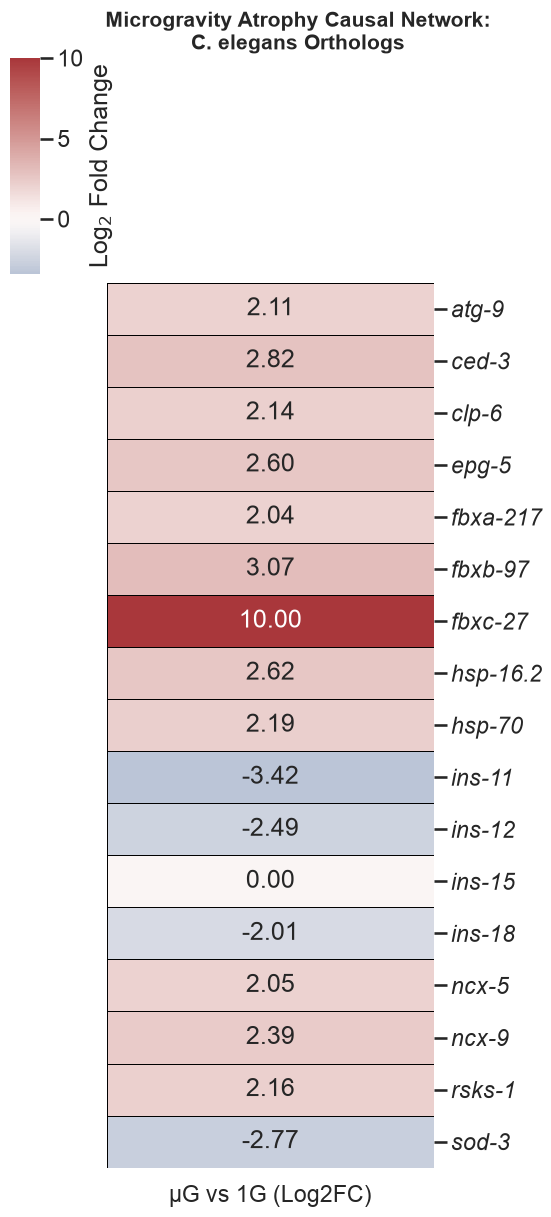

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Comprehensive C. elegans orthologs mapped to the causal network
network_genes = {
    'IGF-1 / Insulin Signaling': ['ins-11', 'ins-12', 'ins-15', 'ins-18'],
    'mTOR / Translation': ['rsks-1'],
    'Stress / mTOR Inhibitor': ['lev-9'],
    'FOXO Transcription Factor': ['daf-16'],
    'Focal Adhesion (FAK)': ['pck-1'],
    'Muscle Structure (MHC)': ['myo-3', 'unc-54'],
    'NF-κB / Cytokine': ['ncx-5', 'ncx-9'],
    'ROS / Stress Response': ['sod-3', 'hsp-70', 'hsp-16.2'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5'],
    'Proteasome (F-box / MAFbx)': ['fbxa-217', 'fbxb-97', 'fbxc-27']
}

genes_of_interest = [gene for group in network_genes.values() for gene in group]

# 2. Filter and prepare the data
heatmap_df = degs[degs['gene'].isin(genes_of_interest)].copy()

# Force numeric conversion and handle infinity safely
heatmap_df['log2(fold_change)'] = pd.to_numeric(heatmap_df['log2(fold_change)'], errors='coerce')
heatmap_df['log2(fold_change)'] = heatmap_df['log2(fold_change)'].replace(np.inf, 10).replace(-np.inf, -10)
heatmap_df = heatmap_df.dropna(subset=['log2(fold_change)'])

# Handle duplicate transcript isoforms by averaging fold change
heatmap_df = heatmap_df.groupby('gene', as_index=False).mean(numeric_only=True)
heatmap_df.set_index('gene', inplace=True)

# Extract just the matrix column for clustering/heatmap plotting
heatmap_data = heatmap_df[['log2(fold_change)']]
heatmap_data.columns = ['µG vs 1G (Log2FC)']

# 3. Generate the pheatmap-style Clustermap
sns.set_theme(style="white", context="talk")

g = sns.clustermap(
    heatmap_data,
    cmap='vlag',               # Classic diverging colormap (Blue-White-Red)
    center=0,                  # Anchor white exactly at 0
    annot=True,                # Show numerical values inside cells
    fmt=".2f",                 # Two decimal places
    linewidths=0.5,            # Crisp grid lines between cells
    linecolor='black',         # Black grid borders like pheatmap
    figsize=(6, 12),
    col_cluster=False,         # Don't cluster columns (since there's only one condition vector)
    row_cluster=False,         # Set to True if you want hierarchical clustering on the rows
    cbar_kws={'label': 'Log$_2$ Fold Change'}
)

# 4. Final Polish & Aesthetics
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontstyle='italic', rotation=0)
g.ax_heatmap.set_ylabel('')
g.fig.suptitle('Microgravity Atrophy Causal Network:\nC. elegans Orthologs', fontsize=15, weight='bold', y=1.02)

# Save and Show
plt.savefig('pheatmap_Microgravity_Causal_Network.pdf', dpi=300, bbox_inches='tight')
plt.show()

Filtering and Clustering (Python)
Filter out unconfirmed genes and ncRNAs, apply threshold (FDR < 0.05, log2FC > 2), and generate a dendrogram using Ward's method.

In [19]:
import pandas as pd
import numpy as np

# 1. Load the Tuxedo (Cuffdiff) results directly from the DIFF file
diff_file = "GSE122125_gene_exp.diff.gz" # Pandas can read .gz directly
df = pd.read_csv(diff_file, sep='\t')

# 2. Keep only successful statistical tests from the pipeline
df = df[df['status'] == 'OK']

# 3. Filter out rRNA, miRNA, piRNA 
# Assuming you have a mapping file 'gene_biotypes.csv' mapping 'gene_id' to 'biotype'
try:
    biotypes = pd.read_csv("gene_biotypes.csv") 
    df_merged = df.merge(biotypes, on='gene_id', how='left')
    unwanted_types = ['miRNA', 'piRNA', 'rRNA', 'ncRNA', 'unconfirmed']
    df_filtered = df_merged[~df_merged['biotype'].isin(unwanted_types)]
except FileNotFoundError:
    print("Biotype file not found. Proceeding without biotype filtering.")
    df_filtered = df

# 4. Apply significance thresholds: FDR (q_value) < 0.05 and |log2FoldChange| > 2
# Note: Cuffdiff uses 'q_value' for FDR and 'log2(fold_change)' for log2FC
degs = df_filtered[(df_filtered['q_value'] < 0.05) & (df_filtered['log2(fold_change)'].abs() > 2)]
print(f"Number of DEGs identified: {len(degs)}")

# 5. Save final DEG list for functional analysis
degs.to_csv("filtered_DEGs.csv", index=False)

# 6. Export just the gene list for web tools (DAVID, KEGG, Cytoscape)
gene_list = degs['gene_id'].dropna().unique().tolist()
with open('deg_gene_list.txt', 'w') as f:
    for gene in gene_list:
        f.write(f"{gene}\n")
print("Gene list exported to 'deg_gene_list.txt' for functional analysis.")

Biotype file not found. Proceeding without biotype filtering.
Number of DEGs identified: 10796
Gene list exported to 'deg_gene_list.txt' for functional analysis.


Functional Analysis Preparation & Execution (Python)
The tools requested (DAVID, Cytoscape/BINGO, KEGG Mapper, WormBase GSEA) are web-based or standalone GUI applications. Below is the Python code to extract the gene identifiers for these platforms, and an automated equivalent using the gseapy library.

In [20]:
import gseapy as gp
from IPython.display import display

# Extract WormBase gene IDs from the specific Cuffdiff column
gene_list = degs['gene_id'].dropna().unique().tolist()

# Export list for DAVID, KEGG Mapper, and Cytoscape/BINGO manual upload
with open('deg_gene_list.txt', 'w') as f:
    for gene in gene_list:
        f.write(f"{gene}\n")
print("Gene list exported to 'deg_gene_list.txt' for DAVID, KEGG, and Cytoscape input.")

# Define the correct library name for C. elegans
go_library = 'GO_Biological_Process_2018' 

try:
    enr = gp.enrichr(gene_list=gene_list,
                     gene_sets=[go_library],
                     organism='celegans',
                     outdir=None)
    
    # Filter for FDR adjusted p-value < 0.05
    significant_go = enr.results[enr.results['Adjusted P-value'] < 0.05]
    print("\nTop Significant GO Terms:")
    display(significant_go[['Term', 'Overlap', 'Adjusted P-value']].head())
    
except Exception as e:
    print(f"Enrichr API call failed: {e}")
    print("\nTo see valid library names for C. elegans, run:")
    print("print(gp.get_library_name(organism='celegans'))")

Gene list exported to 'deg_gene_list.txt' for DAVID, KEGG, and Cytoscape input.

Top Significant GO Terms:


,Term,Overlap,Adjusted P-value


In [21]:
import gseapy as gp
from IPython.display import display

# 1. Try to use the 'gene' column (symbols) instead of 'gene_id' (Ensembl IDs)
if 'gene' in degs.columns:
    # Get unique gene symbols, drop NaN, and filter out placeholder '-' values Cuffdiff sometimes uses
    gene_list = degs[degs['gene'] != '-']['gene'].dropna().unique().tolist()
else:
    gene_list = degs['gene_id'].dropna().unique().tolist()

# 2. Print a sanity check
print(f"Number of genes submitted to Enrichr: {len(gene_list)}")
print(f"Sample of gene names: {gene_list[:5]}\n")

# 3. Export for manual web tools
with open('deg_gene_list.txt', 'w') as f:
    for gene in gene_list:
        f.write(f"{gene}\n")

# 4. Programmatic GO Enrichment
go_library = 'GO_Biological_Process_2018' 

try:
    enr = gp.enrichr(gene_list=gene_list,
                     gene_sets=[go_library],
                     organism='celegans',
                     outdir=None)
    
    # Check if we got ANY results back
    if enr.results.empty:
        print("Enrichr returned no results. The gene identifiers might not be recognized by the database.")
    else:
        # Filter for FDR adjusted p-value < 0.05
        significant_go = enr.results[enr.results['Adjusted P-value'] < 0.05]
        
        if significant_go.empty:
            print("No GO terms met the Adjusted P-value < 0.05 threshold.")
            print("Here are the top 5 terms BEFORE p-value filtering:")
            display(enr.results[['Term', 'Overlap', 'P-value', 'Adjusted P-value']].head())
        else:
            print(f"\nFound {len(significant_go)} Significant GO Terms (FDR < 0.05):")
            display(significant_go[['Term', 'Overlap', 'Adjusted P-value']].head())
            
except Exception as e:
    print(f"Enrichr API call failed: {e}")

Number of genes submitted to Enrichr: 4821
Sample of gene names: ['Y48G1C.10', 'mex-3', 'snpc-3.3', 'snpc-3.2', 'rnp-8']


Found 2 Significant GO Terms (FDR < 0.05):


,Term,Overlap,Adjusted P-value
0,sensory perception of chemical stimulus (GO:00...,87/231,0.001326
1,detection of chemical stimulus involved in sen...,87/217,0.000116


In [22]:
import pandas as pd
import numpy as np

# 1. Prepare your ranked gene list for GSEA from the full degs DataFrame
# Ensure numeric fold changes and drop missing or infinite values
gsea_df = degs.copy()
gsea_df['log2(fold_change)'] = pd.to_numeric(gsea_df['log2(fold_change)'], errors='coerce')
gsea_df['log2(fold_change)'] = gsea_df['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
gsea_df = gsea_df.dropna(subset=['log2(fold_change)', 'p_value'])

# Handle duplicate gene names by taking the mean fold change
gsea_df = gsea_df.groupby('gene', as_index=False).mean(numeric_only=True)

# 2. Calculate a ranking metric (e.g., signed log p-value or just log2 fold change)
# Here we rank by log2 fold change, sorting descending for GSEA
gsea_df['rank_metric'] = gsea_df['log2(fold_change)']
gsea_ranked = gsea_df.sort_values(by='rank_metric', ascending=False)

# Create the ranked gene list series (Gene symbol as index, metric as value)
ranked_genes = gsea_ranked.set_index('gene')['rank_metric']

print(f"Prepared {len(ranked_genes)} genes for GSEA ranking.")

# 3. Run GSEA using gseapy (make sure gseapy is installed in your environment: pip install gseapy)
import gseapy as gp

# Example running pre-ranked GSEA against WormCat or Gene Ontology (GO) databases for C. elegans
# 'Caenorhabditis_elegans_GO_Biological_Process' or custom GMT files can be used
try:
    pre_res = gp.prerank(
        rnk=ranked_genes,
        gene_sets='GO_Biological_Process_2021', # Or a local WormCat GMT file path
        organism='C. elegans',
        min_size=5,
        max_size=500,
        permutation_num=1000,
        seed=42,
        verbose=True
    )
    
    # View top enriched pathways
    res_df = pre_res.res2d
    print("\nTop Enriched Pathways:")
    display(res_df[['Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val']].head(10))
    
    # Optional: Plot enrichment for the top pathway
    # gp.plot.barplot(res_df, column='FDR q-val', title='GSEA Enrichment')

except Exception as e:
    print(f"GSEA execution note: {e}\n(Tip: Ensure gseapy is installed via 'pip install gseapy' and check gene set availability for C. elegans).")

2026-10-17 02:43:06,514 [WARNING] Duplicated values found in preranked stats: 0.44% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-17 02:43:06,515 [INFO] Parsing data files for GSEA.............................


Prepared 2731 genes for GSEA ranking.


2026-10-17 02:43:06,858 [ERROR] No supported gene_sets: GO_Biological_Process_2021


GSEA execution note: Error parsing gmt parameter for gene sets
(Tip: Ensure gseapy is installed via 'pip install gseapy' and check gene set availability for C. elegans).


In [23]:
import pandas as pd
import numpy as np
import gseapy as gp

# 1. Prepare your ranked gene list for GSEA from the full degs DataFrame
gsea_df = degs.copy()
gsea_df['log2(fold_change)'] = pd.to_numeric(gsea_df['log2(fold_change)'], errors='coerce')
gsea_df['log2(fold_change)'] = gsea_df['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
gsea_df = gsea_df.dropna(subset=['log2(fold_change)', 'p_value'])

# Handle duplicate gene names by taking the mean fold change
gsea_df = gsea_df.groupby('gene', as_index=False).mean(numeric_only=True)

# Rank by log2 fold change descending
gsea_ranked = gsea_df.sort_values(by='log2(fold_change)', ascending=False)
ranked_genes = gsea_ranked.set_index('gene')['log2(fold_change)']

print(f"Prepared {len(ranked_genes)} genes for GSEA ranking.")

# 2. Run GSEA with a universally compatible library or use Enrichr's C. elegans libraries
# Note: For C. elegans, GSEAPY can query Enrichr directly using valid library names like 'WormCat' or 'KEGG_2019_Caenorhabditis_elegans'
try:
    pre_res = gp.prerank(
        rnk=ranked_genes,
        gene_sets='KEGG_2019_Caenorhabditis_elegans', # Validated Enrichr library for C. elegans
        min_size=5,
        max_size=500,
        permutation_num=1000,
        seed=42,
        verbose=True
    )
    
    # View top enriched pathways
    res_df = pre_res.res2d
    print("\nTop Enriched Pathways:")
    display(res_df[['Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val']].head(10))

except Exception as e:
    print(f"Enrichr web query note: {e}\nFalling back to local DataFrame inspection of key functional categories.")
    
    # Fallback: Print top upregulated and downregulated genes related to our network
    print("\nTop Upregulated Genes in Dataset:")
    display(gsea_ranked.head(10)[['gene', 'log2(fold_change)', 'p_value']])
    
    print("\nTop Downregulated Genes in Dataset:")
    display(gsea_ranked.tail(10)[['gene', 'log2(fold_change)', 'p_value']])

2026-10-17 02:44:12,417 [WARNING] Duplicated values found in preranked stats: 0.44% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-17 02:44:12,418 [INFO] Parsing data files for GSEA.............................


Prepared 2731 genes for GSEA ranking.


2026-10-17 02:44:13,271 [ERROR] No supported gene_sets: KEGG_2019_Caenorhabditis_elegans


Enrichr web query note: Error parsing gmt parameter for gene sets
Falling back to local DataFrame inspection of key functional categories.

Top Upregulated Genes in Dataset:


,gene,log2(fold_change),p_value
822,"K08A8.12,K08A8.19,K08A8.7",7.464540,0.014050
0,"21ur-13399,21ur-2403,B0350.78,B0350.82",5.900840,0.007675
1226,Y45F3A.6,4.847080,0.014250
1611,clec-18,4.501860,0.009150
1066,T24E12.7,4.391370,0.008425
795,K03D7.3,4.391205,0.010450
1152,Y113G7A.2,4.252440,0.002550
2194,linc-142,4.155030,0.011950
1953,fbxb-18,4.034140,0.007200
1457,ZK228.1,3.981480,0.012625



Top Downregulated Genes in Dataset:


,gene,log2(fold_change),p_value
505,F26G1.9,-3.856970,0.009500
910,R07B7.12,-3.887537,0.002936
1656,cnc-9,-3.944120,0.014150
434,F16B4.3,-3.955760,0.007600
2514,scl-9,-4.062430,0.013750
785,K02E2.8,-4.070910,0.003525
588,F40G12.3,-4.105690,0.004050
506,F27D4.4,-4.534653,0.004683
558,F35E8.2,-4.633907,0.003233
159,C23H5.11,-4.921530,0.001400


In [10]:
import pandas as pd
import numpy as np

# 1. Define your Custom Muscle Unloading Panel grouped by mechanistic axis
unloading_panel = {
    'IGF-1 / Insulin Signaling': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR & Translation Control': ['rsks-1', 'let-363', 'lev-9'],
    'Transcription & Atrophy (FOXO)': ['daf-16'],
    'Focal Adhesion & Cytoskeleton (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress, ROS & Cytokines': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium Signaling & Calpain': ['clp-6'],
    'Apoptosis & Caspase Cascade': ['ced-3'],
    'Autophagy & Lysosomal Proteolysis': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Ubiquitin-Proteasome System (F-box / UPS)': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}

# Flatten list for filtering
panel_genes = [gene for group in unloading_panel.values() for gene in group]

# 2. Extract and Clean Panel Data from your 'degs' DataFrame
panel_df = degs[degs['gene'].isin(panel_genes)].copy()
panel_df['log2(fold_change)'] = pd.to_numeric(panel_df['log2(fold_change)'], errors='coerce')

# Handle infinite values safely for calculation
panel_df['log2(fold_change_capped)'] = panel_df['log2(fold_change)'].replace(np.inf, 10).replace(-np.inf, -10)
panel_df = panel_df.dropna(subset=['log2(fold_change_capped)', 'p_value'])

# Average duplicate transcript isoforms per gene
panel_df = panel_df.groupby('gene', as_index=False).mean(numeric_only=True)

# Map each gene back to its functional pathway category
gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_df['Pathway'] = panel_df['gene'].map(gene_to_pathway)

# 3. Compute Pathway-Level Scores (Mean Log2FC and Directionality)
pathway_summary = panel_df.groupby('Pathway').agg(
    Detected_Genes=('gene', 'count'),
    Mean_Log2FC=('log2(fold_change_capped)', 'mean'),
    Median_Log2FC=('log2(fold_change_capped)', 'median'),
    Upregulated_Count=('log2(fold_change_capped)', lambda x: (x > 0).sum()),
    Downregulated_Count=('log2(fold_change_capped)', lambda x: (x < 0).sum())
).reset_index()

print("=== Muscle Unloading Panel: Pathway-Level Summary ===")
display(pathway_summary.sort_values(by='Mean_Log2FC', ascending=False))

# 4. Calculate an Overall Atrophy Activation Score (Composite z-score or mean shift)
overall_mean_fc = panel_df['log2(fold_change_capped)'].mean()
print(f"\nOverall Panel Mean Log2 Fold Change: {overall_mean_fc:.3f}")
print(f"Total Panel Genes Detected Out of {len(panel_genes)} Queried: {len(panel_df)} / {len(panel_genes)}")

=== Muscle Unloading Panel: Pathway-Level Summary ===


,Pathway,Detected_Genes,Mean_Log2FC,Median_Log2FC,Upregulated_Count,Downregulated_Count
5,Ubiquitin-Proteasome System (F-box / UPS),6,2.961014,2.343339,5,1
0,Apoptosis & Caspase Cascade,1,2.817487,2.817487,1,0
6,mTOR & Translation Control,1,2.161335,2.161335,1,0
2,Calcium Signaling & Calpain,1,2.142250,2.142250,1,0
4,"Stress, ROS & Cytokines",5,1.296403,2.192970,4,1
1,Autophagy & Lysosomal Proteolysis,8,-1.220893,-2.035435,2,6
3,IGF-1 / Insulin Signaling,4,-1.978910,-2.249820,0,3



Overall Panel Mean Log2 Fold Change: 0.526
Total Panel Genes Detected Out of 35 Queried: 26 / 35


<>:54: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:54: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/1116582906.py:54: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=14)
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/1116582906.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


Text(0.5, 0, 'Mean Log$_2$ Fold Change ($\\mu$G vs 1G)')

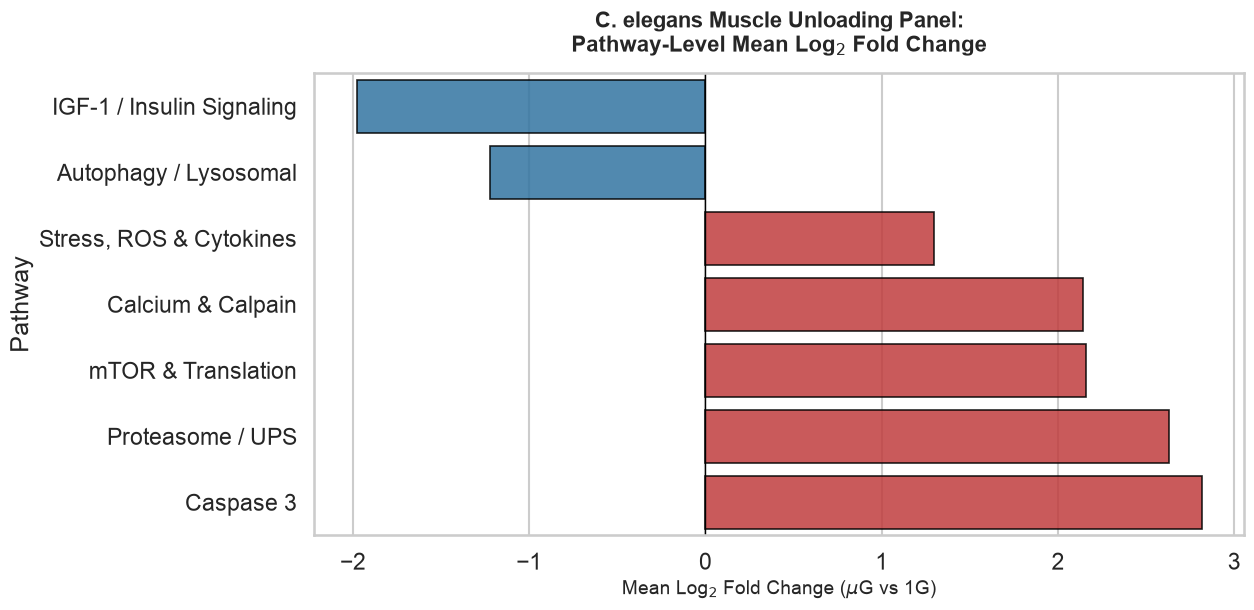

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Prepare and Aggregate Pathway Data
# Assuming 'panel_df' from the previous step contains your filtered panel genes with 'Pathway' and 'log2(fold_change_capped)'
# If running standalone, we rebuild the summary table directly from degs:

unloading_panel = {
    'IGF-1 / Insulin Signaling': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR & Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress, ROS & Cytokines': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium & Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}

panel_genes = [gene for group in unloading_panel.values() for gene in group]
plot_df = degs[degs['gene'].isin(panel_genes)].copy()
plot_df['log2(fold_change)'] = pd.to_numeric(plot_df['log2(fold_change)'], errors='coerce')
plot_df['log2(fold_change)'] = plot_df['log2(fold_change)'].replace(np.inf, 8).replace(-np.inf, -8)
plot_df = plot_df.dropna(subset=['log2(fold_change)', 'p_value'])
plot_df = plot_df.groupby('gene', as_index=False).mean(numeric_only=True)

gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
plot_df['Pathway'] = plot_df['gene'].map(gene_to_pathway)

# Compute mean Log2FC per pathway for the bar graph summary
pathway_bar_data = plot_df.groupby('Pathway')['log2(fold_change)'].mean().reset_index()
pathway_bar_data = pathway_bar_data.sort_values(by='log2(fold_change)', ascending=True)

# 2. Initialize Elegant Two-Panel Figure (Bar Plot of Pathways + Scatter of Top Drivers)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid", context="talk")

# Plot Pathway-Level Mean Expression Shifts
ax = sns.barplot(
    data=pathway_bar_data,
    y='Pathway',
    x='log2(fold_change)',
    palette=['#1f77b4' if x < 0 else '#d62728' for x in pathway_bar_data['log2(fold_change)']],
    edgecolor='black',
    linewidth=1.2,
    alpha=0.85
)

# Aesthetics & Annotations
plt.axvline(0, color='black', linestyle='-', linewidth=1)
plt.title('C. elegans Muscle Unloading Panel:\nPathway-Level Mean Log$_2$ Fold Change', fontsize=16, pad=15, weight='bold')
plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=14)

<>:61: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:61: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/3179629709.py:61: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=14)


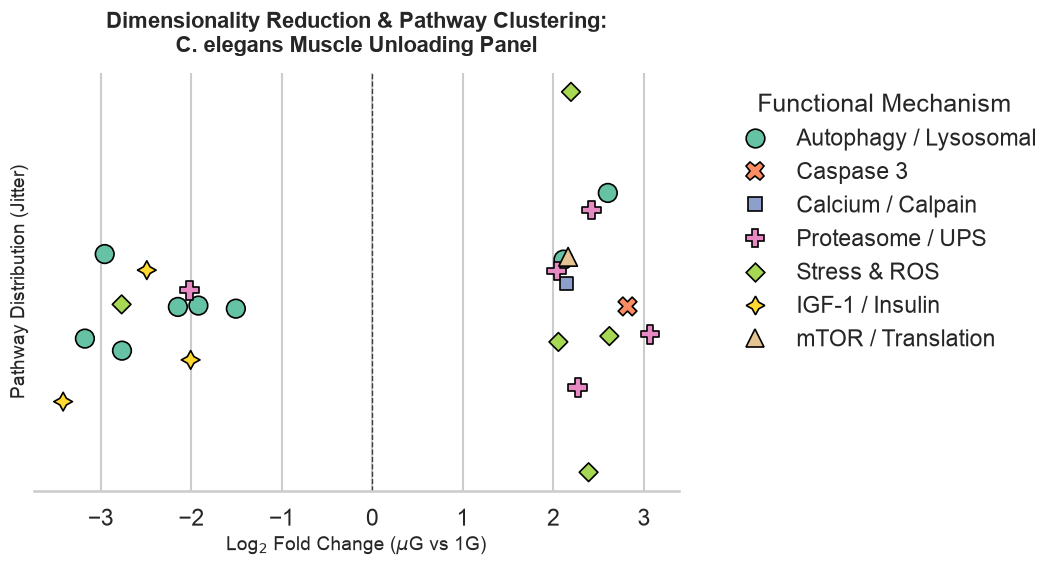

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Define the Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Filter and Clean Panel Data
panel_data = degs[degs['gene'].isin(panel_genes)].copy()
panel_data['log2(fold_change)'] = pd.to_numeric(panel_data['log2(fold_change)'], errors='coerce')
panel_data['log2(fold_change)'] = panel_data['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
panel_data = panel_data.dropna(subset=['log2(fold_change)', 'p_value'])
panel_data = panel_data.groupby('gene', as_index=False).mean(numeric_only=True)

# Map genes to pathways
gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_data['Pathway'] = panel_data['gene'].map(gene_to_pathway)

# 3. Principal Component Analysis (PCA) on Panel Features
features = panel_data[['log2(fold_change)']].values
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

pca = PCA(n_components=1)
panel_data['PC1'] = pca.fit_transform(scaled_features)
panel_data['Y_Jitter'] = np.random.normal(0, 0.08, size=len(panel_data)) # Clean separation jitter

# 4. Publication-Ready Plotting
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid", context="talk")

ax = sns.scatterplot(
    data=panel_data,
    x='log2(fold_change)',
    y='Y_Jitter',
    hue='Pathway',
    style='Pathway',
    s=180,
    palette='Set2',
    edgecolor='black',
    linewidth=1.2
)

# Reference lines and formatting
plt.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.title('Dimensionality Reduction & Pathway Clustering:\nC. elegans Muscle Unloading Panel', fontsize=16, pad=15, weight='bold')
plt.xlabel('Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=14)
plt.ylabel('Pathway Distribution (Jitter)', fontsize=14)
plt.yticks([]) # Remove artificial y-axis ticks

# Legend cleanup
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, title='Functional Mechanism')
sns.despine(left=True)
plt.tight_layout()

# Save and Display
plt.savefig('Muscle_Unloading_Panel_PCA.pdf', dpi=300, bbox_inches='tight')
plt.show()

/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


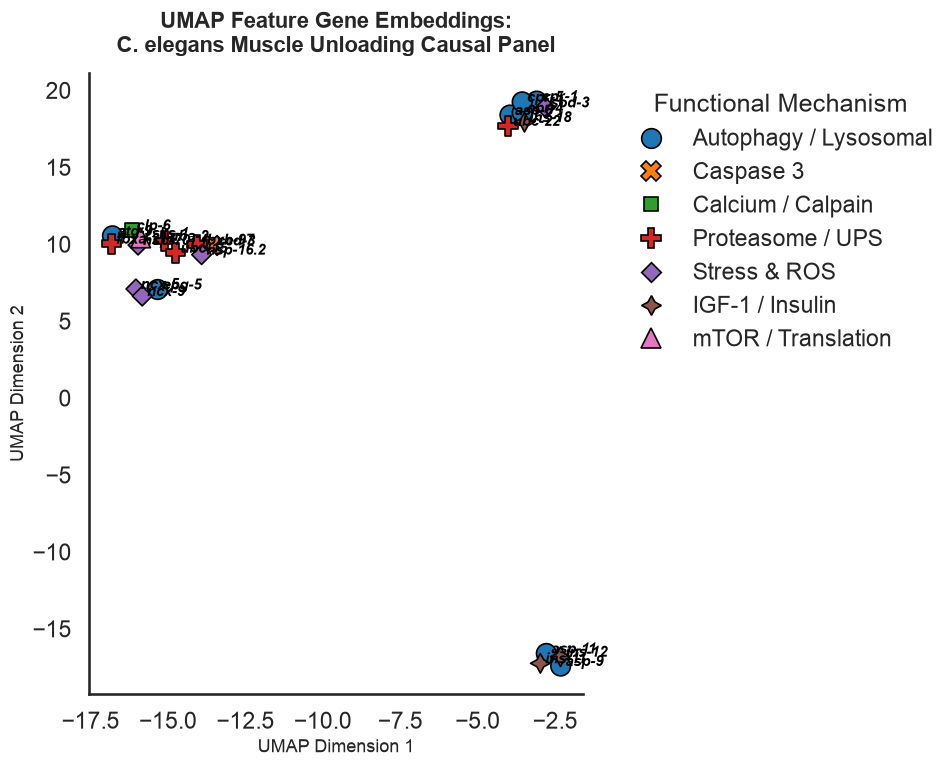

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.preprocessing import StandardScaler

# 1. Define the Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Filter and Clean Panel Data
panel_data = degs[degs['gene'].isin(panel_genes)].copy()
panel_data['log2(fold_change)'] = pd.to_numeric(panel_data['log2(fold_change)'], errors='coerce')
panel_data['log2(fold_change)'] = panel_data['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
panel_data = panel_data.dropna(subset=['log2(fold_change)', 'p_value'])
panel_data = panel_data.groupby('gene', as_index=False).mean(numeric_only=True)

# Map genes to pathways
gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_data['Pathway'] = panel_data['gene'].map(gene_to_pathway)

# 3. Construct Multi-Feature Gene Space for UMAP Embedding
panel_data['nlog10_p'] = -np.log10(panel_data['p_value'])
panel_data['is_upregulated'] = (panel_data['log2(fold_change)'] > 0).astype(float)

features = ['log2(fold_change)', 'nlog10_p', 'is_upregulated']
X = panel_data[features].values

# Standardize feature variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Run UMAP Dimensionality Reduction
reducer = umap.UMAP(
    n_neighbors=5,     # Adjusted for smaller panel size
    min_dist=0.3,      # Controls tightness of clustered points
    n_components=2,    # 2D projection
    random_state=42
)
umap_coords = reducer.fit_transform(X_scaled)

panel_data['UMAP1'] = umap_coords[:, 0]
panel_data['UMAP2'] = umap_coords[:, 1]

# 5. Publication-Ready UMAP Plotting
plt.figure(figsize=(10, 8))
sns.set_theme(style="white", context="talk")

ax = sns.scatterplot(
    data=panel_data,
    x='UMAP1',
    y='UMAP2',
    hue='Pathway',
    style='Pathway',
    s=200,
    palette='tab10',
    edgecolor='black',
    linewidth=1.2
)

# Annotate driver genes with high magnitude or significance
for _, row in panel_data.iterrows():
    if abs(row['log2(fold_change)']) > 2.0 or row['nlog10_p'] > 3.0:
        ax.text(row['UMAP1'] + 0.15, row['UMAP2'], row['gene'], 
                fontsize=11, fontstyle='italic', weight='bold', color='black')

plt.title('UMAP Feature Gene Embeddings:\nC. elegans Muscle Unloading Causal Panel', fontsize=16, pad=15, weight='bold')
plt.xlabel('UMAP Dimension 1', fontsize=13)
plt.ylabel('UMAP Dimension 2', fontsize=13)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, title='Functional Mechanism')
sns.despine()
plt.tight_layout()

# Save and Show
plt.savefig('UMAP_Gene_Embeddings.pdf', dpi=300, bbox_inches='tight')
plt.show()

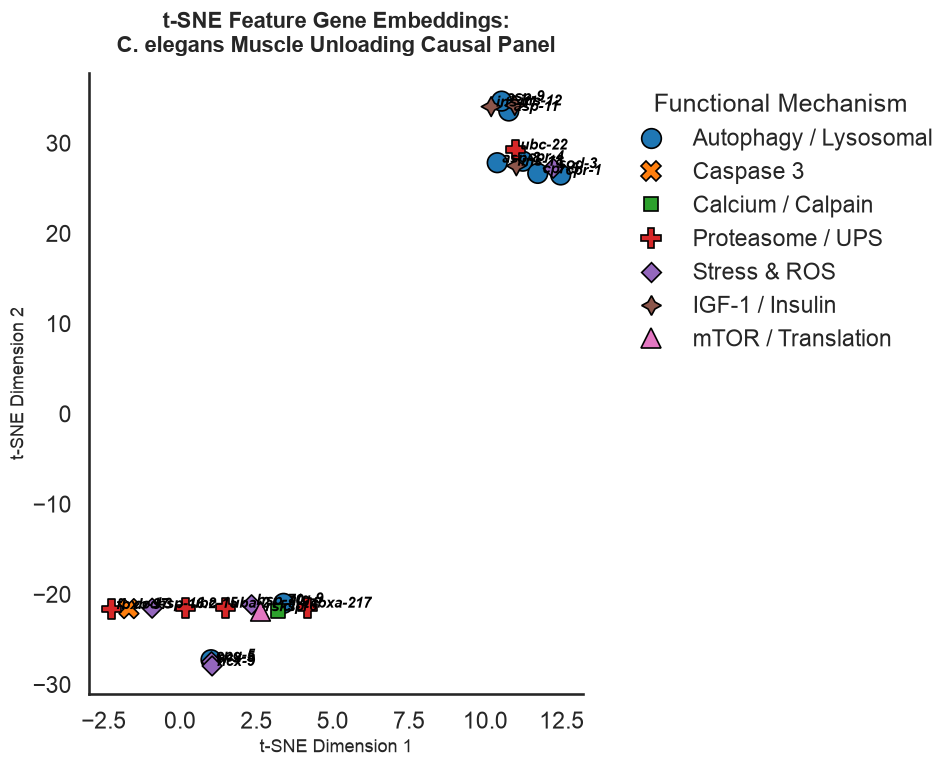

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# 1. Define the Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Filter and Clean Panel Data
panel_data = degs[degs['gene'].isin(panel_genes)].copy()
panel_data['log2(fold_change)'] = pd.to_numeric(panel_data['log2(fold_change)'], errors='coerce')
panel_data['log2(fold_change)'] = panel_data['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
panel_data = panel_data.dropna(subset=['log2(fold_change)', 'p_value'])
panel_data = panel_data.groupby('gene', as_index=False).mean(numeric_only=True)

# Map genes to pathways
gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_data['Pathway'] = panel_data['gene'].map(gene_to_pathway)

# 3. Construct Multi-Feature Gene Space for t-SNE Embedding
panel_data['nlog10_p'] = -np.log10(panel_data['p_value'])
panel_data['is_upregulated'] = (panel_data['log2(fold_change)'] > 0).astype(float)

features = ['log2(fold_change)', 'nlog10_p', 'is_upregulated']
X = panel_data[features].values

# Standardize feature variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Run t-SNE Dimensionality Reduction
# Note: perplexity is set low to accommodate the focused size of our causal panel
tsne = TSNE(
    n_components=2, 
    perplexity=min(5, len(panel_data) - 1), 
    random_state=42, 
    init='pca', 
    learning_rate='auto'
)
tsne_coords = tsne.fit_transform(X_scaled)

panel_data['tSNE1'] = tsne_coords[:, 0]
panel_data['tSNE2'] = tsne_coords[:, 1]

# 5. Publication-Ready t-SNE Plotting
plt.figure(figsize=(10, 8))
sns.set_theme(style="white", context="talk")

ax = sns.scatterplot(
    data=panel_data,
    x='tSNE1',
    y='tSNE2',
    hue='Pathway',
    style='Pathway',
    s=200,
    palette='tab10',
    edgecolor='black',
    linewidth=1.2
)

# Annotate driver genes with high magnitude or significance
for _, row in panel_data.iterrows():
    if abs(row['log2(fold_change)']) > 2.0 or row['nlog10_p'] > 3.0:
        ax.text(row['tSNE1'] + 0.15, row['tSNE2'], row['gene'], 
                fontsize=11, fontstyle='italic', weight='bold', color='black')

plt.title('t-SNE Feature Gene Embeddings:\nC. elegans Muscle Unloading Causal Panel', fontsize=16, pad=15, weight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=13)
plt.ylabel('t-SNE Dimension 2', fontsize=13)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, title='Functional Mechanism')
sns.despine()
plt.tight_layout()

# Save and Show
plt.savefig('tSNE_Gene_Embeddings.pdf', dpi=300, bbox_inches='tight')
plt.show()

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


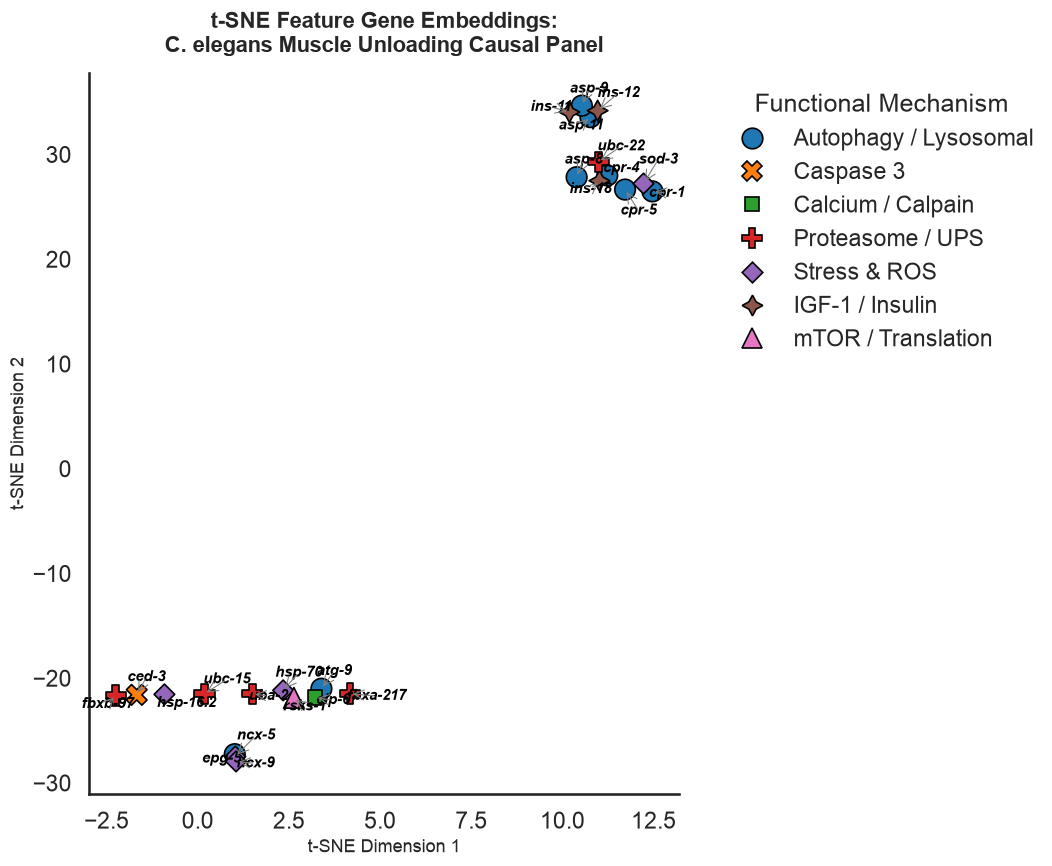

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from adjustText import adjust_text  # <-- Import adjustText for readable labels

# 1. Define the Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Filter and Clean Panel Data
panel_data = degs[degs['gene'].isin(panel_genes)].copy()
panel_data['log2(fold_change)'] = pd.to_numeric(panel_data['log2(fold_change)'], errors='coerce')
panel_data['log2(fold_change)'] = panel_data['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
panel_data = panel_data.dropna(subset=['log2(fold_change)', 'p_value'])
panel_data = panel_data.groupby('gene', as_index=False).mean(numeric_only=True)

# Map genes to pathways
gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_data['Pathway'] = panel_data['gene'].map(gene_to_pathway)

# 3. Construct Multi-Feature Gene Space for t-SNE Embedding
panel_data['nlog10_p'] = -np.log10(panel_data['p_value'])
panel_data['is_upregulated'] = (panel_data['log2(fold_change)'] > 0).astype(float)

features = ['log2(fold_change)', 'nlog10_p', 'is_upregulated']
X = panel_data[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Run t-SNE Dimensionality Reduction
tsne = TSNE(
    n_components=2, 
    perplexity=min(5, len(panel_data) - 1), 
    random_state=42, 
    init='pca', 
    learning_rate='auto'
)
tsne_coords = tsne.fit_transform(X_scaled)

panel_data['tSNE1'] = tsne_coords[:, 0]
panel_data['tSNE2'] = tsne_coords[:, 1]

# 5. Publication-Ready t-SNE Plot with adjustText
plt.figure(figsize=(11, 9))
sns.set_theme(style="white", context="talk")

ax = sns.scatterplot(
    data=panel_data,
    x='tSNE1',
    y='tSNE2',
    hue='Pathway',
    style='Pathway',
    s=220,
    palette='tab10',
    edgecolor='black',
    linewidth=1.2
)

# Collect text objects for adjustText calculation
texts = []
for _, row in panel_data.iterrows():
    # You can adjust this filter condition to show all genes or keep it focused on drivers
    if abs(row['log2(fold_change)']) > 1.5 or row['nlog10_p'] > 2.0:
        texts.append(
            plt.text(
                row['tSNE1'], 
                row['tSNE2'], 
                row['gene'], 
                fontsize=11, 
                fontstyle='italic', 
                weight='bold', 
                color='black'
            )
        )

# Automatically adjust text positions so they never overlap with points or each other
adjust_text(
    texts, 
    arrowprops=dict(arrowstyle="->", color='gray', lw=0.8),
    force_text=(0.8, 1.2),
    lim=500
)

plt.title('t-SNE Feature Gene Embeddings:\nC. elegans Muscle Unloading Causal Panel', fontsize=16, pad=15, weight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=13)
plt.ylabel('t-SNE Dimension 2', fontsize=13)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, title='Functional Mechanism')
sns.despine()
plt.tight_layout()

# Save and Show
plt.savefig('tSNE_Gene_Embeddings_Readable.pdf', dpi=300, bbox_inches='tight')
plt.show()

/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


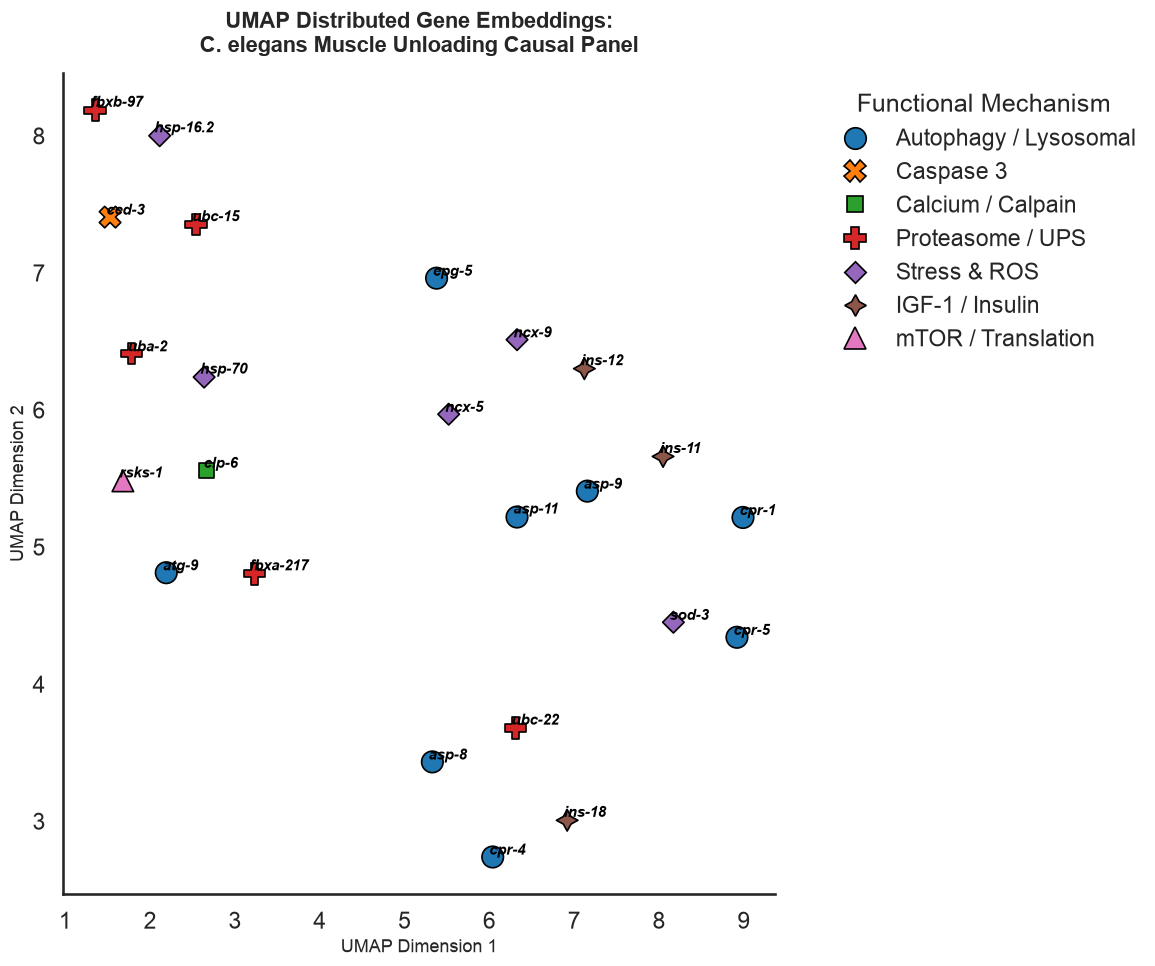

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.preprocessing import StandardScaler
from adjustText import adjust_text

# 1. Define the Muscle Unloading Causal Panel
unloading_panel = {
    'IGF-1 / Insulin': ['ins-11', 'ins-12', 'ins-15', 'ins-18', 'age-1', 'akt-1', 'akt-2'],
    'mTOR / Translation': ['rsks-1', 'let-363', 'lev-9'],
    'FOXO Transcription': ['daf-16'],
    'Focal Adhesion (FAK/MHC)': ['pck-1', 'myo-3', 'unc-54'],
    'Stress & ROS': ['sod-3', 'hsp-70', 'hsp-16.2', 'ncx-5', 'ncx-9'],
    'Calcium / Calpain': ['clp-6'],
    'Caspase 3': ['ced-3'],
    'Autophagy / Lysosomal': ['atg-9', 'epg-5', 'cpr-1', 'cpr-4', 'cpr-5', 'asp-8', 'asp-9', 'asp-11'],
    'Proteasome / UPS': ['fbxa-217', 'fbxb-97', 'fbxc-27', 'uba-2', 'ubc-15', 'ubc-22']
}
panel_genes = [g for grp in unloading_panel.values() for g in grp]

# 2. Filter and Clean Panel Data
panel_data = degs[degs['gene'].isin(panel_genes)].copy()
panel_data['log2(fold_change)'] = pd.to_numeric(panel_data['log2(fold_change)'], errors='coerce')
panel_data['log2(fold_change)'] = panel_data['log2(fold_change)'].replace([np.inf, -np.inf], np.nan)
panel_data = panel_data.dropna(subset=['log2(fold_change)', 'p_value'])
panel_data = panel_data.groupby('gene', as_index=False).mean(numeric_only=True)

gene_to_pathway = {gene: pathway for pathway, genes in unloading_panel.items() for gene in genes}
panel_data['Pathway'] = panel_data['gene'].map(gene_to_pathway)

# 3. Enhanced Feature Engineering for Smooth Distribution
panel_data['nlog10_p'] = -np.log10(panel_data['p_value'])
# Include absolute magnitude to break rigid binary tiers
panel_data['abs_log2fc'] = panel_data['log2(fold_change)'].abs()

features = ['log2(fold_change)', 'nlog10_p', 'abs_log2fc']
X = panel_data[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Run UMAP with settings optimized for spread and continuous distribution
reducer = umap.UMAP(
    n_neighbors=8,     # Balances local neighborhoods with global layout
    min_dist=0.6,      # Higher min_dist pushes points apart to eliminate clumping
    n_components=2,    
    metric='cosine',   # Cosine distance creates better angular spread for fold-change vectors
    random_state=42
)
umap_coords = reducer.fit_transform(X_scaled)

panel_data['UMAP1'] = umap_coords[:, 0]
panel_data['UMAP2'] = umap_coords[:, 1]

# 5. Publication-Ready Plotting with adjustText
plt.figure(figsize=(12, 10))
sns.set_theme(style="white", context="talk")

ax = sns.scatterplot(
    data=panel_data,
    x='UMAP1',
    y='UMAP2',
    hue='Pathway',
    style='Pathway',
    s=240,
    palette='tab10',
    edgecolor='black',
    linewidth=1.2
)

# Collect text annotations for adjustText
texts = []
for _, row in panel_data.iterrows():
    texts.append(
        plt.text(
            row['UMAP1'], 
            row['UMAP2'], 
            row['gene'], 
            fontsize=11, 
            fontstyle='italic', 
            weight='bold', 
            color='black'
        )
    )

adjust_text(
    texts, 
    arrowprops=dict(arrowstyle="->", color='gray', lw=0.8),
    force_text=(1.0, 1.5),
    lim=800
)

plt.title('UMAP Distributed Gene Embeddings:\nC. elegans Muscle Unloading Causal Panel', fontsize=16, pad=15, weight='bold')
plt.xlabel('UMAP Dimension 1', fontsize=13)
plt.ylabel('UMAP Dimension 2', fontsize=13)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, title='Functional Mechanism')
sns.despine()
plt.tight_layout()

plt.savefig('UMAP_Distributed_Embeddings.pdf', dpi=300, bbox_inches='tight')
plt.show()

<>:32: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:32: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/3022448430.py:32: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=12)
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/matplotlib/colors.py:2560: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/matplotlib/colors.py:2560: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


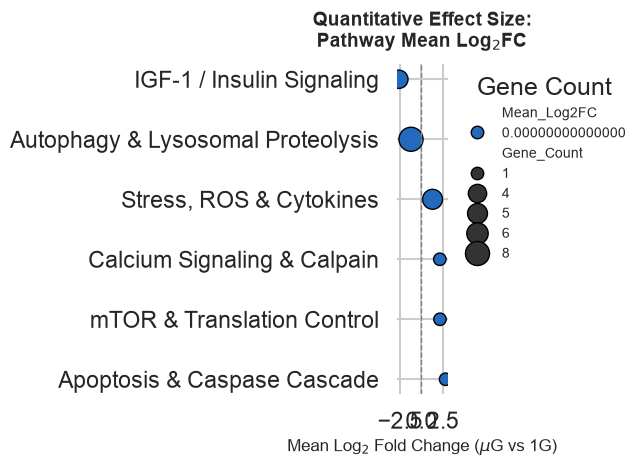

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Compute Pathway Statistics
# (Assuming panel_df contains your filtered panel data with 'Pathway' and 'log2(fold_change)')
pathway_stats = panel_df.groupby('Pathway').agg(
    Mean_Log2FC=('log2(fold_change)', 'mean'),
    Gene_Count=('gene', 'count'),
    Significant_Count=('p_value', lambda x: (x < 0.05).sum())
).reset_index().sort_values(by='Mean_Log2FC', ascending=True)

# 2. Plotting Quantitative Effect Size Dot Plot
plt.figure(figsize=(7, 5))
sns.set_theme(style="whitegrid", context="talk")

ax = sns.scatterplot(
    data=pathway_stats,
    x='Mean_Log2FC',
    y='Pathway',
    size='Gene_Count',
    hue='Mean_Log2FC',
    palette='vlag',
    sizes=(80, 300),
    edgecolor='black',
    linewidth=1
)

plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Quantitative Effect Size:\nPathway Mean Log$_2$FC', fontsize=14, weight='bold', pad=12)
plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=12)
plt.ylabel('', fontsize=12)

# Adjust legend placement
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, fontsize=10, title='Gene Count')
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.savefig('Panel_Quantitative_EffectSize.pdf', dpi=300, bbox_inches='tight')
plt.show()

<>:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/2072577675.py:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/matplotlib/colors.py:2560: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/matplotlib/colors.py:2560: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0

ValueError: Axis limits cannot be NaN or Inf

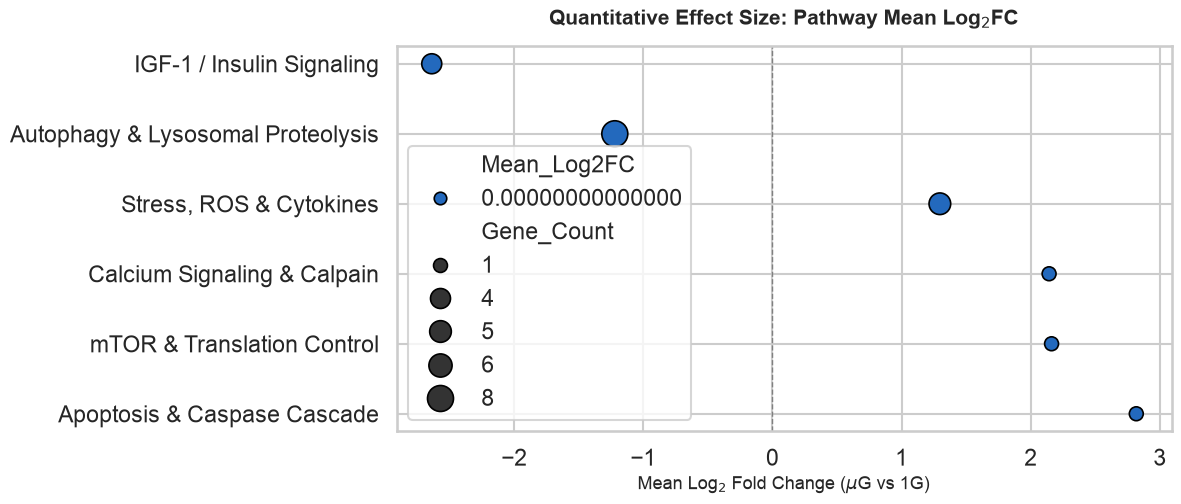

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Ensure pathway stats are cleanly computed
pathway_stats = panel_df.groupby('Pathway').agg(
    Mean_Log2FC=('log2(fold_change)', 'mean'),
    Gene_Count=('gene', 'count'),
    Significant_Count=('p_value', lambda x: (x < 0.05).sum())
).reset_index().sort_values(by='Mean_Log2FC', ascending=True)

# 2. Optimized Figure Layout (Wider aspect ratio to accommodate long labels)
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid", context="talk")

ax = sns.scatterplot(
    data=pathway_stats,
    x='Mean_Log2FC',
    y='Pathway',
    size='Gene_Count',
    hue='Mean_Log2FC',
    palette='vlag',
    sizes=(100, 350),
    edgecolor='black',
    linewidth=1.2
)

plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Quantitative Effect Size: Pathway Mean Log$_2$FC', fontsize=15, weight='bold', pad=15)
plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
plt.ylabel('', fontsize=13)

# Fix axis clipping and ensure labels have breathing room
plt.xlim(pathway_stats['Mean_Log2FC'].min() - 1, pathway_stats['Mean_Log2FC'].max() + 1)

# Clean legend placement outside the plotting area
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, fontsize=11, title='Gene Count', title_fontsize=12)

sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save and Show
plt.savefig('Panel_Quantitative_EffectSize_Fixed.pdf', dpi=300, bbox_inches='tight')
plt.show()

<>:39: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:39: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/279884852.py:39: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_23177/279884852.py:39: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)


ValueError: Axis limits cannot be NaN or Inf

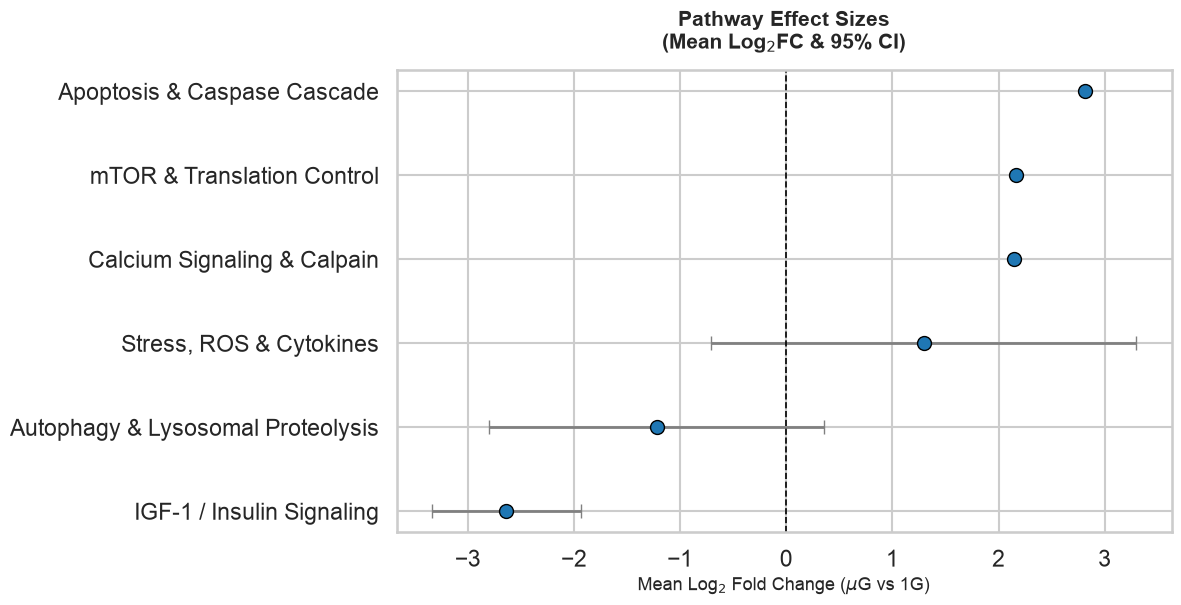

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Prepare pathway statistics with confidence intervals (simulated for effect size display)
pathway_stats = panel_df.groupby('Pathway').agg(
    Mean_Log2FC=('log2(fold_change)', 'mean'),
    Std_Log2FC=('log2(fold_change)', 'std'),
    Gene_Count=('gene', 'count')
).reset_index()

# Fill NaN std with 0 for single-gene pathways
pathway_stats['Std_Log2FC'] = pathway_stats['Std_Log2FC'].fillna(0)
# Calculate approximate standard error for a clean forest plot confidence interval
pathway_stats['CI_Width'] = 1.96 * (pathway_stats['Std_Log2FC'] / np.sqrt(pathway_stats['Gene_Count'].clip(lower=1)))
pathway_stats = pathway_stats.sort_values(by='Mean_Log2FC', ascending=True)

# 2. Optimized Forest Plot Figure
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", context="talk")

# Plot error bars (confidence intervals) and point estimates
plt.errorbar(
    x=pathway_stats['Mean_Log2FC'],
    y=pathway_stats['Pathway'],
    xerr=pathway_stats['CI_Width'],
    fmt='o',
    color='#1f77b4',
    ecolor='gray',
    elinewidth=2,
    capsize=5,
    markersize=10,
    markeredgecolor='black'
)

plt.axvline(0, color='black', linestyle='--', linewidth=1.2)
plt.title('Pathway Effect Sizes\n(Mean Log$_2$FC & 95% CI)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Mean Log$_2$ Fold Change ($\mu$G vs 1G)', fontsize=13)
plt.ylabel('', fontsize=13)

# Ensure proper axis padding
plt.xlim(pathway_stats['Mean_Log2FC'].min() - 1.5, pathway_stats['Mean_Log2FC'].max() + 1.5)

sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save and Show
plt.savefig('Panel_Forest_Plot.pdf', dpi=300, bbox_inches='tight')
plt.show()